In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Example directed web graph.
# Each key is a page and its list contains pages linked from it.
graph = {
    "A": ["B", "C"],
    "B": ["C", "D"],
    "C": ["A"],
    "D": ["C", "E"],
    "E": ["A", "D"]
}

print("Web graph:")
for page, links in graph.items():
    print(f"{page} -> {links}")

Web graph:
A -> ['B', 'C']
B -> ['C', 'D']
C -> ['A']
D -> ['C', 'E']
E -> ['A', 'D']


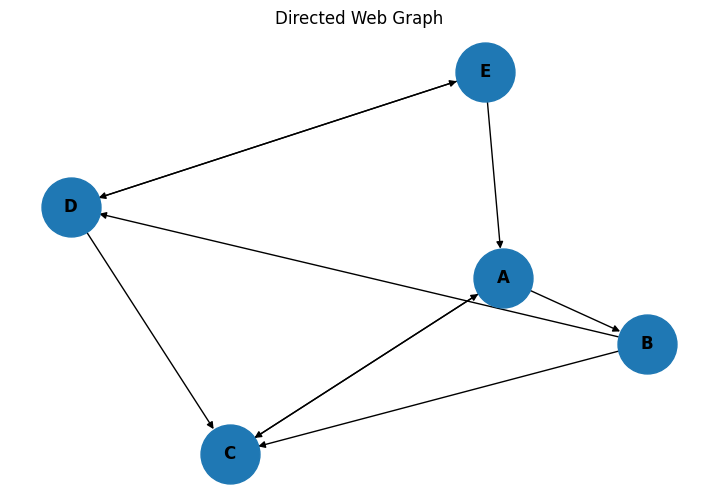

In [3]:
G = nx.DiGraph()

for source, destinations in graph.items():
    for destination in destinations:
        G.add_edge(source, destination)

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(9, 6))
nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    arrows=True,
    font_weight="bold"
)
plt.title("Directed Web Graph")
plt.axis("off")
plt.show()

In [4]:
def pagerank(graph, damping=0.85, max_iterations=100, tolerance=1e-8):
    pages = list(graph.keys())
    n = len(pages)
    page_index = {page: i for i, page in enumerate(pages)}

    # Ensure every linked page is represented.
    for links in graph.values():
        for page in links:
            if page not in page_index:
                page_index[page] = len(pages)
                pages.append(page)

    n = len(pages)
    rank = np.ones(n) / n

    # Build incoming-link structure.
    incoming = {page: [] for page in pages}
    outgoing_count = {page: len(graph.get(page, [])) for page in pages}

    for source in pages:
        for destination in graph.get(source, []):
            incoming[destination].append(source)

    history = [rank.copy()]

    for iteration in range(1, max_iterations + 1):
        new_rank = np.ones(n) * ((1 - damping) / n)

        for page in pages:
            i = page_index[page]

            for source in incoming[page]:
                out_degree = outgoing_count.get(source, 0)

                if out_degree > 0:
                    new_rank[i] += damping * (
                        rank[page_index[source]] / out_degree
                    )

        # Handle dangling nodes by redistributing their rank uniformly.
        dangling_rank = sum(
            rank[page_index[p]]
            for p in pages
            if outgoing_count.get(p, 0) == 0
        )
        new_rank += damping * dangling_rank / n

        history.append(new_rank.copy())

        if np.linalg.norm(new_rank - rank, ord=1) < tolerance:
            rank = new_rank
            print(f"Converged after {iteration} iterations.")
            break

        rank = new_rank

    return {page: rank[page_index[page]] for page in pages}, history

scores, history = pagerank(graph)

results = (
    pd.DataFrame({
        "Page": list(scores.keys()),
        "PageRank": list(scores.values())
    })
    .sort_values("PageRank", ascending=False)
    .reset_index(drop=True)
)

results["Rank"] = np.arange(1, len(results) + 1)

display(results)

Converged after 45 iterations.


,Page,PageRank,Rank
0,A,0.316571,1
1,C,0.292920,2
2,B,0.164543,3
3,D,0.137520,4
4,E,0.088446,5


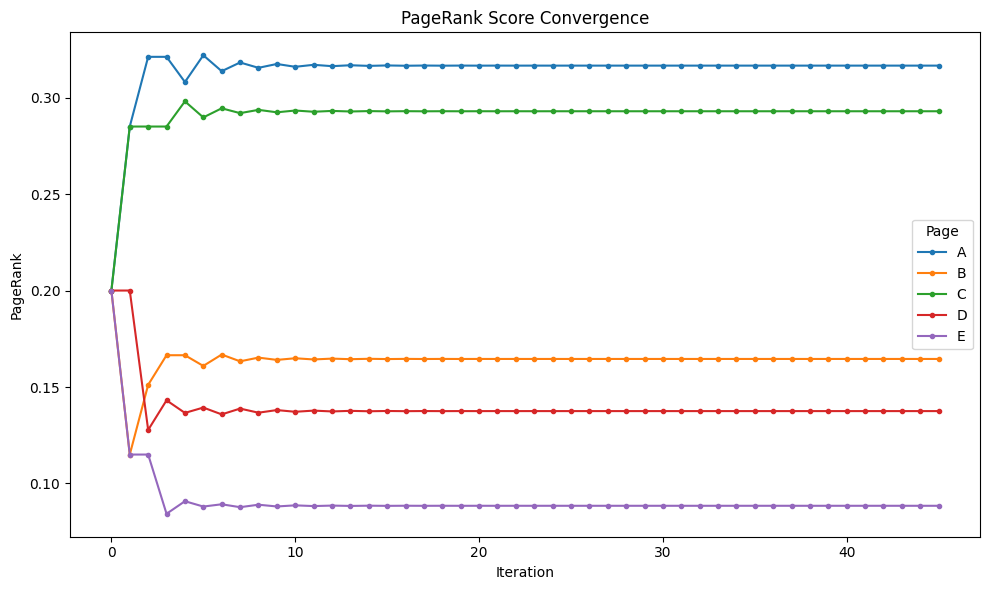

In [5]:
history_array = np.array(history)

plt.figure(figsize=(10, 6))
for i, page in enumerate(scores.keys()):
    plt.plot(history_array[:, i], marker=".", label=page)

plt.title("PageRank Score Convergence")
plt.xlabel("Iteration")
plt.ylabel("PageRank")
plt.legend(title="Page")
plt.tight_layout()
plt.show()

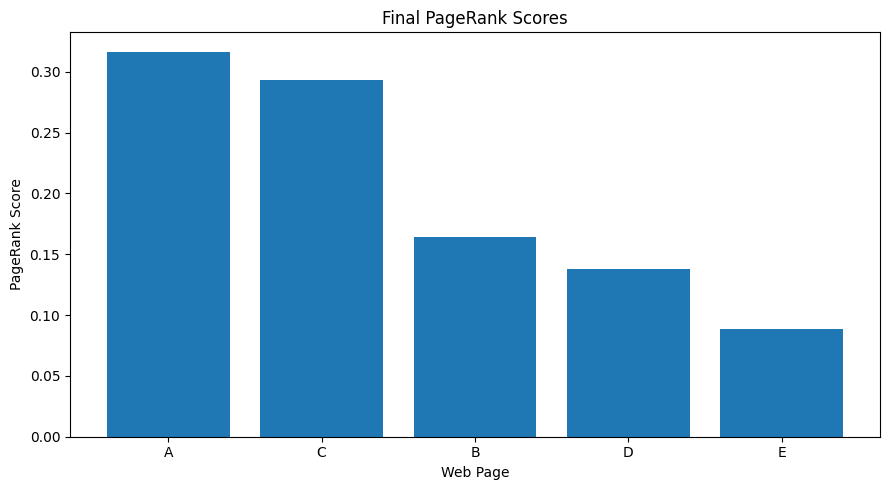

PageRank scores:


,Page,PageRank,Rank
0,A,0.316571,1
1,C,0.292920,2
2,B,0.164543,3
3,D,0.137520,4
4,E,0.088446,5


In [6]:
plt.figure(figsize=(9, 5))
plt.bar(results["Page"], results["PageRank"])
plt.title("Final PageRank Scores")
plt.xlabel("Web Page")
plt.ylabel("PageRank Score")
plt.tight_layout()
plt.show()

print("PageRank scores:")
display(results)

In [7]:
highest_page = results.iloc[0]["Page"]
highest_score = results.iloc[0]["PageRank"]

print(f"Highest PageRank in this graph: {highest_page}")
print(f"PageRank score: {highest_score:.6f}")

print("\nInterpretation:")
print("- A page receives a higher score when it is linked by pages that themselves have higher PageRank.")
print("- The damping factor models the probability that a user continues following links.")
print("- Iteration continues until the PageRank vector converges or the maximum iteration count is reached.")

Highest PageRank in this graph: A
PageRank score: 0.316571

Interpretation:
- A page receives a higher score when it is linked by pages that themselves have higher PageRank.
- The damping factor models the probability that a user continues following links.
- Iteration continues until the PageRank vector converges or the maximum iteration count is reached.


In [ ]:
# 🌐 PageRank Algorithm (मराठीत)

## भाग 1: Basic Terms

| Term | सोप्या भाषेत अर्थ |
|---|---|
| **PageRank** | Google चे संस्थापक Larry Page आणि Sergey Brin यांचा algorithm. Web pages ना त्यांच्याकडे येणाऱ्या links वरून महत्त्व (score) देतो |
| **Web Graph** | Web = graph. प्रत्येक page = **node**, प्रत्येक hyperlink = **directed edge** (बाण) |
| **Directed Graph** | बाणाला दिशा असते. A→B म्हणजे A ने B ला link दिलंय, पण B ने A ला दिलंच असं नाही |
| **Inlink (Backlink)** | इतर pages कडून आपल्या page कडे येणारी link |
| **Outlink** | आपल्या page कडून इतर pages कडे जाणारी link |
| **Out-degree** | एका page वर किती outlinks आहेत त्याची संख्या |
| **Damping Factor (d)** | User link follow करत राहण्याची probability (साधारण 0.85). उरलेली (1−d) = 0.15 म्हणजे user कंटाळून random page वर जातो |
| **Random Surfer Model** | एक कल्पित user जो random links क्लिक करत फिरतो. PageRank = तो user कोणत्या page वर किती वेळ असेल त्याची probability |
| **Teleportation** | (1−d) संभाव्यतेने user कोणत्याही page वर उडी मारतो |
| **Dangling Node** | असं page ज्याला एकही outlink नाही (dead end) |
| **Convergence** | Iterations करत गेल्यावर score बदलणं थांबून स्थिर होणं |
| **Tolerance** | दोन iterations मधला फरक एवढ्या छोट्या मूल्यापेक्षा कमी झाला की थांबतो (इथे 1e-8) |
| **L1 Norm** | फरकांची absolute values ची बेरीज |

**मुख्य सूत्र:**

**PR(p) = (1 − d)/N + d × Σ [ PR(q) / L(q) ]**

- N = एकूण pages
- q = p कडे link करणारे pages
- L(q) = q ची out-degree

**कल्पना:** जो page महत्त्वाच्या pages कडून link मिळवतो, तो स्वतः महत्त्वाचा. एक पान आपला score आपल्या outlinks मध्ये समान वाटतं.

---

## भाग 2: Line-by-Line Explanation

### Cell 1: Imports

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
```
- `numpy`: arrays आणि गणित.
- `pandas`: results ची table बनवायला.
- `matplotlib`: graphs काढायला.
- `networkx`: graph तयार करायला आणि काढायला (nodes/edges).

```python
plt.rcParams["figure.figsize"] = (10, 6)
```
सर्व plots चा default आकार ठरवतो.

### Cell 2: Web Graph

```python
graph = {
    "A": ["B", "C"],
    "B": ["C", "D"],
    "C": ["A"],
    "D": ["C", "E"],
    "E": ["A", "D"]
}
```
**Adjacency list** पद्धतीने graph. Key = page, value = त्या page वरून जाणारे outlinks. उदा. A ने B आणि C ला link दिलंय.

```python
for page, links in graph.items():
    print(f"{page} -> {links}")
```
`.items()` ने key आणि value दोन्ही मिळतात. प्रत्येक page चे outlinks छापतो.

### Cell 3: Graph Draw करणे

```python
G = nx.DiGraph()
```
रिकामा **directed graph** object. (`Graph()` असता तर बाण नसते.)

```python
for source, destinations in graph.items():
    for destination in destinations:
        G.add_edge(source, destination)
```
Dictionary मधल्या प्रत्येक link साठी एक edge (बाण) जोडतो. Nodes आपोआप तयार होतात.

```python
pos = nx.spring_layout(G, seed=42)
```
Nodes ची जागा (coordinates) ठरवतो. `seed=42` दिल्याने प्रत्येक वेळी तोच layout येतो.

```python
nx.draw_networkx(G, pos, with_labels=True, node_size=1800, arrows=True, font_weight="bold")
```
- `with_labels=True`: nodes वर A, B... नावं.
- `node_size=1800`: वर्तुळ मोठं.
- `arrows=True`: दिशा दाखवणारे बाण.
- `font_weight="bold"`: नावं ठळक.

```python
plt.title("Directed Web Graph")
plt.axis("off")
plt.show()
```
Title, axes लपवतो (graph साठी गरज नाही), आणि चित्र दाखवतो.

### Cell 4: PageRank Function (सर्वात महत्त्वाचा भाग)

```python
def pagerank(graph, damping=0.85, max_iterations=100, tolerance=1e-8):
```
Parameters: damping factor, कमाल iterations (अनंत loop टाळायला), आणि थांबण्याची tolerance.

```python
pages = list(graph.keys())
n = len(pages)
page_index = {page: i for i, page in enumerate(pages)}
```
- सर्व pages ची list.
- `page_index`: प्रत्येक page ला number (A→0, B→1...). **का?** Rank numpy array मध्ये ठेवलाय, आणि array ला index लागतो.

```python
for links in graph.values():
    for page in links:
        if page not in page_index:
            page_index[page] = len(pages)
            pages.append(page)
```
काही page फक्त link म्हणून आला असेल पण key नसेल (outlinks नसलेला page), तर त्याला list मध्ये जोडतो. **का?** म्हणजे कोणताही page सुटू नये. या graph मध्ये सर्व pages keys आहेत, म्हणून काही जोडलं जात नाही.

```python
n = len(pages)
rank = np.ones(n) / n
```
`n` पुन्हा मोजतो (नवीन pages जोडले असतील तर). **सुरुवातीचा rank सर्वांना समान** = 1/5 = 0.2.

```python
incoming = {page: [] for page in pages}
outgoing_count = {page: len(graph.get(page, [])) for page in pages}

for source in pages:
    for destination in graph.get(source, []):
        incoming[destination].append(source)
```
- `outgoing_count`: प्रत्येक page ची out-degree. `graph.get(page, [])` मुळे key नसलेल्या page साठी 0.
- `incoming`: "कोणकोणते pages या page कडे link करतात" ही उलटी map.
- **का?** सूत्रात page p चा score हा त्याच्याकडे येणाऱ्या pages वर अवलंबून असतो.

या graph साठी:

| Page | Incoming |
|---|---|
| A | C, E |
| B | A |
| C | A, B, D |
| D | B, E |
| E | D |

```python
history = [rank.copy()]
```
प्रत्येक iteration चा rank साठवतो (convergence graph साठी). `.copy()` आवश्यक, नाहीतर सर्व entries एकाच array ला point करतील.

```python
for iteration in range(1, max_iterations + 1):
    new_rank = np.ones(n) * ((1 - damping) / n)
```
प्रत्येक iteration ला नवीन rank बनवतो. सुरुवात **teleportation भाग (1−d)/N** ने = 0.15/5 = 0.03 प्रत्येकाला.

```python
for page in pages:
    i = page_index[page]
    for source in incoming[page]:
        out_degree = outgoing_count.get(source, 0)
        if out_degree > 0:
            new_rank[i] += damping * (rank[page_index[source]] / out_degree)
```
सूत्रातला **d × Σ PR(q)/L(q)** भाग:
- प्रत्येक page साठी त्याच्याकडे येणारे pages (`source`) पाहतो.
- Source चा जुना rank त्याच्या out-degree ने भागतो (rank outlinks मध्ये समान वाटला जातो).
- `damping` ने गुणून `new_rank` मध्ये जोडतो.
- `out_degree > 0` तपासणी म्हणजे शून्याने भागणं (ZeroDivisionError) टाळणं.

```python
dangling_rank = sum(rank[page_index[p]] for p in pages if outgoing_count.get(p, 0) == 0)
new_rank += damping * dangling_rank / n
```
**Dangling nodes** चा rank कुठेच जात नाही, म्हणून तो सर्व pages मध्ये समान वाटतो. यामुळे एकूण rank ची बेरीज 1 राहते. या graph मध्ये dangling node नसल्याने `dangling_rank = 0` आहे.

```python
history.append(new_rank.copy())

if np.linalg.norm(new_rank - rank, ord=1) < tolerance:
    rank = new_rank
    print(f"Converged after {iteration} iterations.")
    break

rank = new_rank
```
- नवीन rank history मध्ये ठेवतो.
- जुना आणि नवा rank यातील फरक (L1 norm) tolerance पेक्षा कमी असेल तर **converge झालं**, loop थांबतो.
- नाहीतर `rank = new_rank` करून पुढच्या iteration ची तयारी.

```python
return {page: rank[page_index[page]] for page in pages}, history
```
दोन गोष्टी परत करतो: प्रत्येक page चा final score (dictionary) आणि पूर्ण history.

```python
scores, history = pagerank(graph)
```
Function चालवतो (default values सह).

```python
results = (
    pd.DataFrame({"Page": list(scores.keys()), "PageRank": list(scores.values())})
    .sort_values("PageRank", ascending=False)
    .reset_index(drop=True)
)
results["Rank"] = np.arange(1, len(results) + 1)
display(results)
```
Scores ची table बनवतो, मोठ्यापासून लहानाकडे sort करतो, index पुन्हा 0 पासून लावतो आणि 1, 2, 3... असा Rank column जोडतो.

### Cell 5: Convergence Graph

```python
history_array = np.array(history)
```
List of arrays → 2D array. Rows = iterations, columns = pages.

```python
for i, page in enumerate(scores.keys()):
    plt.plot(history_array[:, i], marker=".", label=page)
```
प्रत्येक page साठी एक रेषा. `[:, i]` = सर्व iterations मधला i-th page चा rank. X-axis = iteration, Y-axis = score. **का?** काही iterations नंतर रेषा आडव्या (स्थिर) होतात, म्हणजे convergence दिसतं.

### Cell 6: Bar Chart

```python
plt.bar(results["Page"], results["PageRank"])
```
Final scores चा bar chart, ज्यातून तुलना सहज दिसते.

### Cell 7: Result आणि Interpretation

```python
highest_page = results.iloc[0]["Page"]
highest_score = results.iloc[0]["PageRank"]
```
Table sorted असल्याने पहिली row (`iloc[0]`) = सर्वाधिक rank असलेलं page.

Interpretation print होतात: महत्त्वाच्या pages कडून link मिळाली तर score जास्त, damping factor म्हणजे user link follow करत राहण्याची probability, आणि convergence होईपर्यंत iterations चालतात.

### अपेक्षित Output (मी हाताने सोडवून काढलेली अंदाजे values)

| Page | PageRank (≈) |
|---|---|
| **A** | **0.317** |
| C | 0.293 |
| B | 0.165 |
| D | 0.138 |
| E | 0.088 |

बेरीज = 1. **सर्वाधिक = A**, कारण A ला C (C चे सर्व rank A कडेच जातात, कारण C चा एकच outlink A आहे) आणि E कडून link मिळते. तुमच्या Colab मध्ये आलेले आकडे तपासून पाहा, ते यांच्या जवळपास असावेत.

---

## भाग 3: Viva Q&A

**Q1. PageRank म्हणजे काय?**
उत्तर: Web pages चं महत्त्व मोजणारा link-analysis algorithm. जास्त आणि महत्त्वाच्या pages कडून link मिळाली की page चा score जास्त.

**Q2. PageRank चं सूत्र सांगा.**
उत्तर: PR(p) = (1−d)/N + d × Σ PR(q)/L(q)

**Q3. Damping factor म्हणजे काय? साधारण किती असतो?**
उत्तर: User link follow करत राहण्याची probability. साधारणपणे 0.85. उरलेली 0.15 म्हणजे user random page वर जाण्याची शक्यता.

**Q4. Damping factor का लागतो?**
उत्तर: (1) Dead ends आणि spider traps मध्ये rank अडकू नये, (2) algorithm converge होण्याची खात्री, (3) प्रत्येक page ला किमान काही score मिळावा.

**Q5. Random Surfer Model म्हणजे काय?**
उत्तर: एक user जो random links क्लिक करतो आणि कधीतरी कंटाळून नवीन page वर जातो. Long run मध्ये तो एखाद्या page वर असण्याची probability = त्याचा PageRank.

**Q6. Dangling node म्हणजे काय? ते कसं हाताळलं?**
उत्तर: ज्या page ला outlinks नाहीत. त्याचा rank सर्व pages मध्ये समान वाटला (`dangling_rank / n`), म्हणजे एकूण rank 1 राहतो.

**Q7. Spider trap म्हणजे काय?**
उत्तर: Pages चा असा गट ज्यांच्या links फक्त आपसातच असतात आणि बाहेर जात नाहीत. त्यात सर्व rank अडकतो. Teleportation (damping) ने ही समस्या सुटते.

**Q8. Convergence म्हणजे काय? कसं तपासलं?**
उत्तर: Iterations मध्ये score बदलणं थांबून स्थिर होणं. जुन्या आणि नव्या rank मधला फरक (L1 norm) tolerance (1e-8) पेक्षा कमी झाला की convergence.

**Q9. सुरुवातीला rank 1/N का दिला?**
उत्तर: सुरुवातीला कोणत्याही page बद्दल माहिती नसते, म्हणून सर्वांना समान महत्त्व. Iterations मध्ये ते सुधारत जातं.

**Q10. सर्व PageRank ची बेरीज किती असते?**
उत्तर: 1. कारण ही probability distribution आहे.

**Q11. PageRank कोणत्या गणिती संकल्पनेवर आधारित आहे?**
उत्तर: **Markov Chain** च्या stationary distribution वर. Transition matrix चा principal **eigenvector** म्हणजे PageRank vector. हा **Power Iteration method** ने काढतात (इथे वापरलेली iterative पद्धत).

**Q12. Inlink आणि Outlink मध्ये फरक?**
उत्तर: Inlink = इतर pages कडून आपल्याकडे येणारी link. Outlink = आपल्याकडून इतर pages कडे जाणारी. PageRank inlinks वर अवलंबून असतो.

**Q13. फक्त inlinks जास्त असले की rank जास्त का?**
उत्तर: नाही. **Inlinks ची गुणवत्ता** महत्त्वाची. एका महत्त्वाच्या page ची link अनेक कमी महत्त्वाच्या pages पेक्षा जास्त मोलाची. तसंच त्या source page चे outlinks जितके कमी, तितका वाटा मोठा.

**Q14. या graph मध्ये A चा rank सर्वाधिक का आला?**
उत्तर: A ला C आणि E कडून link आहे. C चा एकमेव outlink A कडेच असल्याने C चा पूर्ण rank A ला मिळतो. त्यामुळे A सर्वाधिक.

**Q15. `incoming` dictionary का बनवली?**
उत्तर: PageRank सूत्रात page चा score त्याच्याकडे येणाऱ्या pages वरून काढायचा असतो, म्हणून "कोण कोणाला link करतं" ही उलटी map लागते.

**Q16. `max_iterations` का दिलं?**
उत्तर: जर काही कारणाने convergence झालं नाही तर loop अनंत चालू नये म्हणून सुरक्षा मर्यादा.

**Q17. PageRank चे तोटे / मर्यादा?**
उत्तर: (1) Link spam / link farms द्वारे फसवता येतं, (2) जुन्या pages ला फायदा होतो (नवीन pages ला inlinks कमी), (3) query शी संबंधित नसतो, फक्त popularity मोजतो, (4) खूप मोठ्या graph साठी गणन जड.

**Q18. PageRank आणि HITS algorithm मध्ये फरक?**
उत्तर: PageRank प्रत्येक page ला **एकच** score देतो. HITS दोन score देतो: **Hub** (चांगल्या pages कडे link करणारा) आणि **Authority** (अनेक hubs कडून link मिळवलेला). तसंच HITS query-dependent असतो, PageRank नाही.

**Q19. PageRank हा Information Retrieval मध्ये कुठे वापरतात?**
उत्तर: Search engines मध्ये results चं ranking करताना (Google). Text relevance सोबत PageRank एकत्र करून अंतिम क्रम ठरतो. तसंच social network analysis, citation analysis, recommendation मध्येही.

**Q20. `nx.DiGraph()` आणि `nx.Graph()` मध्ये फरक?**
उत्तर: DiGraph = directed (बाणाला दिशा), Graph = undirected. Web links ला दिशा असते, म्हणून DiGraph.

**Q21. NetworkX मध्ये आधीच PageRank function आहे का?**
उत्तर: हो, `nx.pagerank(G, alpha=0.85)`. इथे ते स्वतः लिहून algorithm समजावून दाखवलाय. Examiner ने विचारलं तर सांगता येईल की दोघांचे निकाल जवळजवळ सारखेच येतात.

---

## ⚠️ Viva साठी महत्त्वाच्या टिपा

1. **`n` दोन वेळा काढलाय** (`n = len(pages)` वर आणि खाली पुन्हा). खाली पुन्हा काढणं गरजेचं, कारण मधल्या loop मध्ये नवीन pages जोडले जाऊ शकतात.
2. या graph मध्ये **dangling node नाही**, म्हणून तो भाग प्रत्यक्षात काही बदल करत नाही. पण function सामान्य graphs साठीही बरोबर चालेल अशा प्रकारे लिहिलंय.
3. `display()` हे Colab/Jupyter चं function आहे, साध्या script मध्ये `print()` वापरा.
4. `history` चे columns `scores.keys()` च्या क्रमाने आहेत, म्हणून convergence plot मधली legend बरोबर जुळते.
5. **Convergence किती iterations मध्ये झालं** तो आकडा output मध्ये छापलेला दिसेल, तो आधी पाहून ठेवा, कारण examiner विचारू शकतो.

All the best! 🙂 पुढचा code आला की पाठव.